# A toy digital twin: calibrating a tank model against sensor data

**Everything here is a toy example.** The "real" tank is simulated too, with a valve coefficient the model does not know and with sensor noise added. The point is the loop that makes a model a digital twin:

1. a physics model predicts the level,
2. sensor data shows the prediction is off,
3. calibration moves a model parameter until model and data agree.

Model: $A \, \frac{dh}{dt} = q_{in} - k\sqrt{h}$, where the outflow through the valve follows Torricelli's law.

Run it: `uv run --with numpy --with matplotlib --with jupyterlab jupyter lab sim/`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tank

plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

## 1. The model with the datasheet value

The datasheet says `k = 0.010`. With that value the model predicts the tank settles at 4.00 m.

predicted steady level: 4.00 m


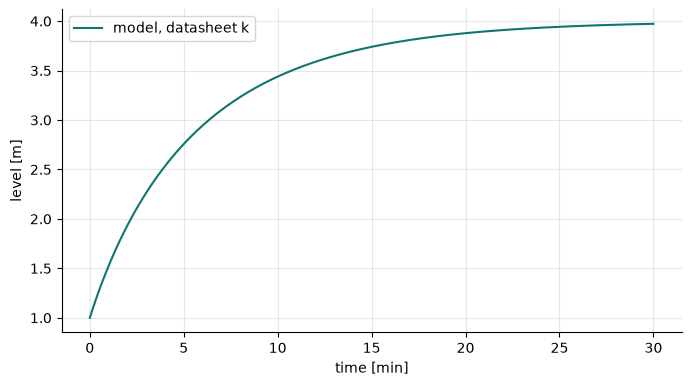

In [2]:
t, h_model = tank.simulate(tank.K_GUESS)
print(f"predicted steady level: {tank.steady_state(tank.K_GUESS):.2f} m")
plt.plot(t / 60, h_model, color="#0F766E", label="model, datasheet k")
plt.xlabel("time [min]"); plt.ylabel("level [m]"); plt.legend(); plt.show()

## 2. What the sensor says

The level sensor reports every 10 s with about 2 cm of noise. The readings flatten out far below the prediction.

181 readings, RMSE of the datasheet model: 0.946 m


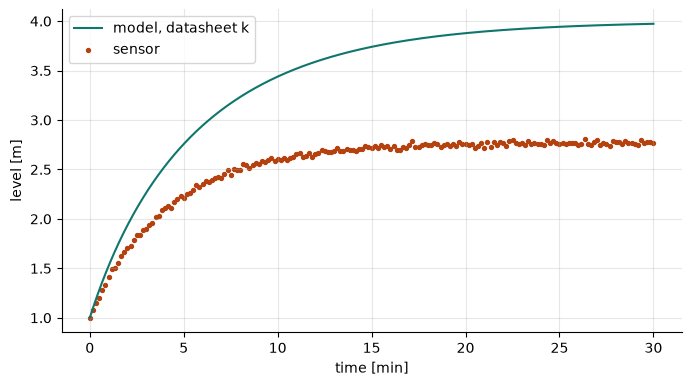

In [3]:
t_obs, h_obs = tank.sensor()
print(f"{len(t_obs)} readings, RMSE of the datasheet model: {tank.rmse(tank.K_GUESS, t_obs, h_obs):.3f} m")
plt.plot(t / 60, h_model, color="#0F766E", label="model, datasheet k")
plt.scatter(t_obs / 60, h_obs, s=8, color="#B4410E", label="sensor")
plt.xlabel("time [min]"); plt.ylabel("level [m]"); plt.legend(); plt.show()

## 3. Calibrate

One unknown, so a grid search is enough: try 141 values of `k` and keep the one with the lowest error against the readings.

calibrated k = 0.0120, RMSE = 0.018 m


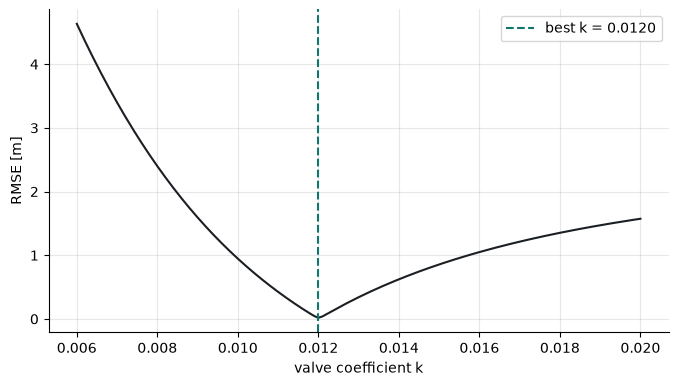

In [4]:
grid = np.linspace(0.006, 0.020, 141)
errors = [tank.rmse(k, t_obs, h_obs) for k in grid]
k_fit = tank.calibrate(t_obs, h_obs)
print(f"calibrated k = {k_fit:.4f}, RMSE = {tank.rmse(k_fit, t_obs, h_obs):.3f} m")
plt.plot(grid, errors, color="#1B1F23")
plt.axvline(k_fit, color="#0F766E", ls="--", label=f"best k = {k_fit:.4f}")
plt.xlabel("valve coefficient k"); plt.ylabel("RMSE [m]"); plt.legend(); plt.show()

## 4. The calibrated twin

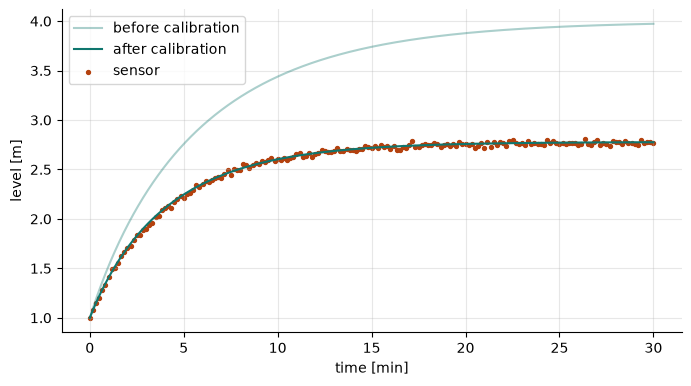

steady level: 4.00 m predicted before, 2.78 m after


In [5]:
_, h_fit = tank.simulate(k_fit)
plt.plot(t / 60, h_model, color="#0F766E", alpha=0.35, label="before calibration")
plt.plot(t / 60, h_fit, color="#0F766E", label="after calibration")
plt.scatter(t_obs / 60, h_obs, s=8, color="#B4410E", label="sensor")
plt.xlabel("time [min]"); plt.ylabel("level [m]"); plt.legend(); plt.show()
print(f"steady level: {tank.steady_state(tank.K_GUESS):.2f} m predicted before, {tank.steady_state(k_fit):.2f} m after")

## What this toy leaves out

- A real plant has more than one unknown, and parameters drift, so calibration runs continuously, not once.
- The remaining error (about 2 cm) is the sensor noise I added. On real data, a residual with a pattern means the model is missing physics.
- A 20% error in one coefficient moved the predicted steady level from 4.00 m to 2.78 m. Small parameter errors can be large prediction errors when the model is nonlinear.